# 10 - Phân tích đơn biến trên dữ liệu giá nhà Amsterdam

Mục tiêu: bài mẫu 1.3.2 (bài toán 1 nhiệm vụ 2): boxplot, violin plot và `describe()` cho `Price`.

## 1. Load data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

houses = pd.read_csv(can_file('HousingPricesData.csv'), usecols=lambda c: c in ['Zip', 'Price', 'Area', 'Room'])
kiem_tra_chat_luong(houses, 'Amsterdam house prices')
houses['Price'] = pd.to_numeric(houses['Price'], errors='coerce')
houses['Price_trieu'] = houses['Price'] / 1e6  

=== Amsterdam house prices ===
Shape: (924, 4)
Số dòng trùng lặp: 6
Giá trị thiếu theo cột:
Price    4
dtype: int64


## 2. Boxplot

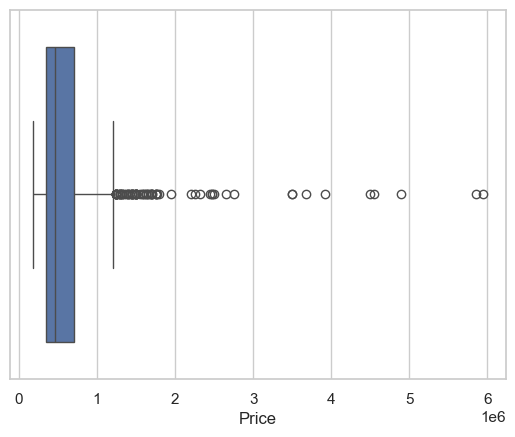

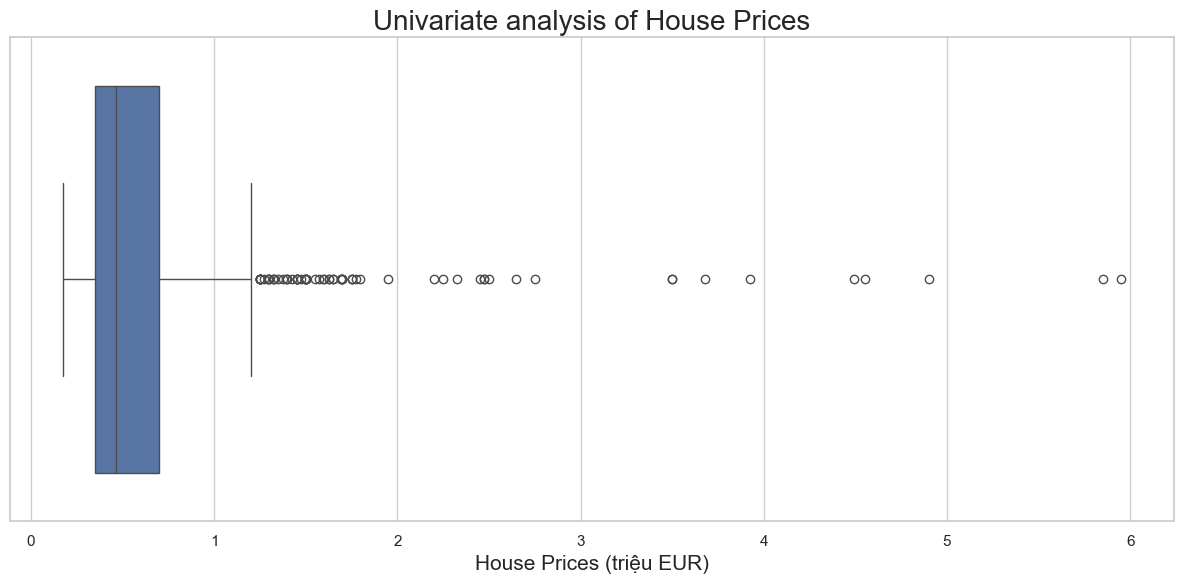

In [2]:
sns.boxplot(data=houses, x='Price')
plt.show()

plt.figure(figsize=(12, 6))
ax = sns.boxplot(data=houses, x='Price_trieu')
ax.set_xlabel('House Prices (triệu EUR)', fontsize=15)
ax.set_title('Univariate analysis of House Prices', fontsize=20)
luu_hinh('10_houseprices_boxplot')

## 3. Violin plot

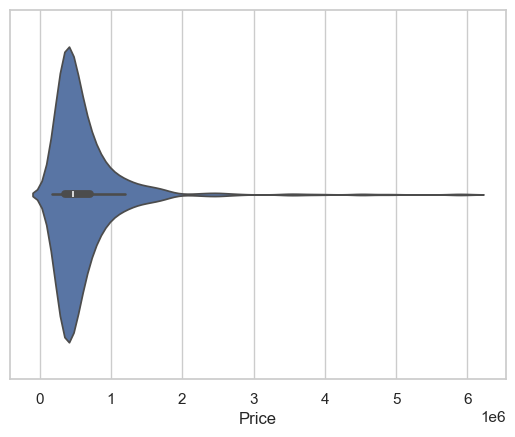

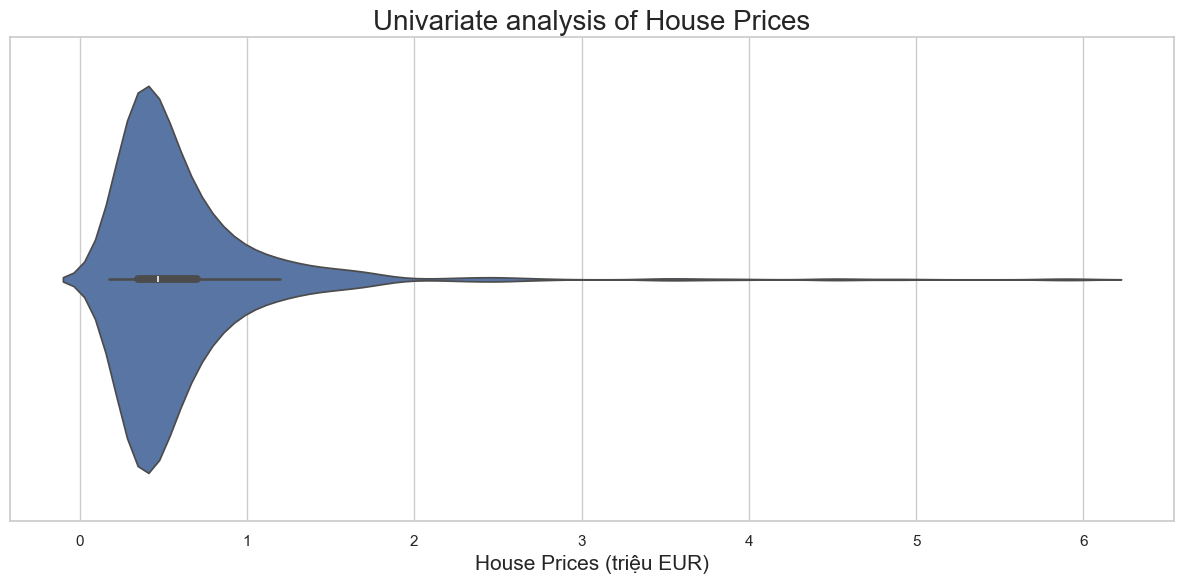

In [3]:
sns.violinplot(data=houses, x='Price')
plt.show()

plt.figure(figsize=(12, 6))
ax = sns.violinplot(data=houses, x='Price_trieu')
ax.set_xlabel('House Prices (triệu EUR)', fontsize=15)
ax.set_title('Univariate analysis of House Prices', fontsize=20)
luu_hinh('10_houseprices_violin')

## 4. Bảng tóm tắt và ngoại lai

,Price
count,9.200000e+02
mean,6.220654e+05
std,5.389942e+05
min,1.750000e+05
25%,3.500000e+05
50%,4.670000e+05
75%,7.000000e+05
max,5.950000e+06


IQR = 350,000 | hàng rào ngoại lai: [-175,000, 1,225,000] | số ngoại lai: 71 (7.7%)
mean = 622,065 | median = 467,000 | skew = 4.83


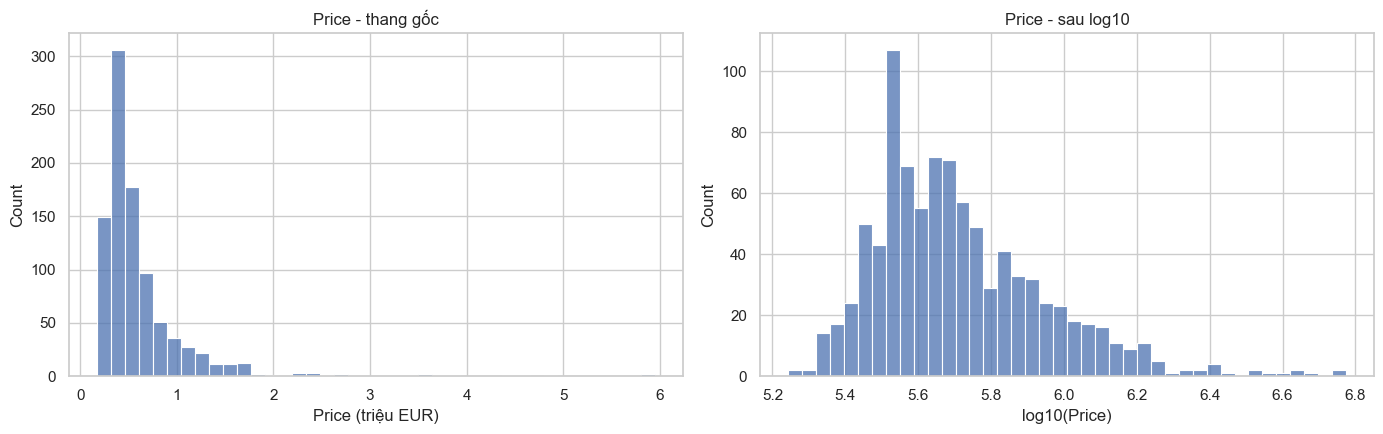

Đã cập nhật: results_summary.csv


In [4]:
display(houses[['Price']].describe())
price = houses['Price'].dropna()
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = int(((price < low) | (price > high)).sum())
print(f'IQR = {iqr:,.0f} | hàng rào ngoại lai: [{low:,.0f}, {high:,.0f}] | số ngoại lai: {n_out} ({n_out / len(price) * 100:.1f}%)')
print(f'mean = {price.mean():,.0f} | median = {price.median():,.0f} | skew = {price.skew():.2f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(price / 1e6, bins=40, ax=axes[0]); axes[0].set_xlabel('Price (triệu EUR)'); axes[0].set_title('Price - thang gốc')
sns.histplot(np.log10(price), bins=40, ax=axes[1]); axes[1].set_xlabel('log10(Price)'); axes[1].set_title('Price - sau log10')
luu_hinh('10_houseprices_price_log')
cap_nhat_summary('10_houseprices_univariate', 'HousingPricesData.csv', houses[['Price', 'Area', 'Room']])

## 5. Nhận xét

`Price` lệch phải mạnh: mean cao hơn median rõ rệt và có nhiều ngoại lai ở phía giá cao (các căn cao cấp), nên trung vị mô tả giá "điển hình" tốt hơn. Violin plot cho thấy phần lớn căn tập trung ở vùng giá thấp với đuôi dài, còn boxplot chỉ ra riêng các ngoại lai. Biến đổi log10 làm phân bố cân đối hơn, phù hợp nếu dùng làm biến mục tiêu cho hồi quy sau này. Một số dòng thiếu `Price` bị loại tự động khi vẽ và tính `describe()`.